# Exploración de datos (EDA): Conteos Censales 2009-2024
Carga `Datos/datos_procesados/concatenacion/concatenacion_2009-2024.csv` completo en un `DataFrame` (`data`, ~55 millones de filas; cada fila es un grupo de personas por sección × sexo × edad × elección) y revisa su calidad y su comportamiento antes de limpiarlo: valores nulos, outliers, distribución de las variables, estados, distritos electorales, correlaciones, participación, abstención, sexo y edad.

**Antes de correr:** el CSV debe haberse generado con `notebooks/concatenacion/concatenacion_2009-2024.ipynb` (13 variables). Se necesitan ~6 GB de memoria libre para la lectura.

Definiciones usadas:
- `SV`: votaron. `NV`: no votaron. `NS`: no especificado (se desconoce si votaron). `LN = SV + NV + NS`.
- Participación = `SV / (SV + NV)`.
- Abstención = `NV / (SV + NV)`.
- `NS` queda fuera de ambas tasas y se analiza aparte como indicador de calidad del dato: `NS / LN`.

Los hallazgos de este análisis (sexo sin definir, edades imposibles, `DEF` vacío, nombres de municipios) se aplican en `notebooks/limpieza/limpieza.ipynb`.


In [64]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:,.3f}".format
pd.options.display.max_rows = 100

In [65]:
_cwd = Path.cwd().resolve()
RAIZ = next(p for p in [_cwd, *_cwd.parents] if (p / "Datos").is_dir())
ARCHIVO = RAIZ / "Datos" / "datos_procesados" / "concatenacion" / "concatenacion_2009-2024.csv"

print("Archivo:", ARCHIVO)
print(f"Existe: {ARCHIVO.exists()} | Tamaño: {ARCHIVO.stat().st_size / 1e9:.2f} GB")

Archivo: C:\Users\camil\Documents\Programming\INE\Datos\datos_procesados\concatenacion_2009-2024.csv
Existe: True | Tamaño: 3.32 GB


## 1. Lectura e información inicial

In [66]:
data = pd.read_csv(ARCHIVO)
data.head(10)

C:\Users\camil\AppData\Local\Temp\ipykernel_19124\1545289605.py:1: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(ARCHIVO)


,AELEC,FELECCION,EDONOM,MPIONOM,SECCION,DEF,TIPOSEC,SEXO,EDAD,LN,SV,NV,NS
0,2009,5/7/2009,AGUASCALIENTES,Aguascalientes,1,3,U,0,18,31,11,20,0
1,2009,5/7/2009,AGUASCALIENTES,Aguascalientes,1,3,U,0,19,20,7,13,0
2,2009,5/7/2009,AGUASCALIENTES,Aguascalientes,1,3,U,0,20,28,9,19,0
3,2009,5/7/2009,AGUASCALIENTES,Aguascalientes,1,3,U,0,21,21,9,12,0
4,2009,5/7/2009,AGUASCALIENTES,Aguascalientes,1,3,U,0,22,30,12,18,0
5,2009,5/7/2009,AGUASCALIENTES,Aguascalientes,1,3,U,0,23,20,5,15,0
6,2009,5/7/2009,AGUASCALIENTES,Aguascalientes,1,3,U,0,24,20,5,15,0
7,2009,5/7/2009,AGUASCALIENTES,Aguascalientes,1,3,U,0,25,24,8,16,0
8,2009,5/7/2009,AGUASCALIENTES,Aguascalientes,1,3,U,0,26,17,4,13,0
9,2009,5/7/2009,AGUASCALIENTES,Aguascalientes,1,3,U,0,27,21,6,15,0


In [67]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54872712 entries, 0 to 54872711
Data columns (total 13 columns):
 #   Column     Dtype 
---  ------     ----- 
 0   AELEC      int64 
 1   FELECCION  object
 2   EDONOM     object
 3   MPIONOM    object
 4   SECCION    int64 
 5   DEF        object
 6   TIPOSEC    object
 7   SEXO       int64 
 8   EDAD       int64 
 9   LN         int64 
 10  SV         int64 
 11  NV         int64 
 12  NS         int64 
dtypes: int64(8), object(5)
memory usage: 5.3+ GB


In [68]:
data.describe()

,AELEC,SECCION,SEXO,EDAD,LN,SV,NV,NS
count,"54,872,712.000","54,872,712.000","54,872,712.000","54,872,712.000","54,872,712.000","54,872,712.000","54,872,712.000","54,872,712.000"
mean,"2,016.718","1,585.669",0.506,52.699,9.450,4.933,4.086,0.430
std,5.129,"1,350.909",0.500,21.030,12.264,6.273,6.875,2.187
min,"2,009.000",1.000,0.000,18.000,1.000,0.000,0.000,0.000
25%,"2,012.000",544.000,0.000,35.000,3.000,1.000,1.000,0.000
50%,"2,018.000","1,228.000",1.000,52.000,6.000,3.000,2.000,0.000
75%,"2,021.000","2,247.000",1.000,70.000,12.000,7.000,5.000,0.000
max,"2,024.000","9,004.000",2.000,140.000,982.000,424.000,603.000,259.000


## 2. Valores nulos

In [69]:
nulos = {}
for col in data.columns:
    if pd.api.types.is_numeric_dtype(data[col]):      # numéricas: solo pueden ser NaN
        nulos[col] = data[col].isnull().sum()
    else:                                             # texto: NaN o espacios en blanco
        nulos[col] = (data[col].isnull() | (data[col].str.strip() == "")).sum()

pd.Series(nulos, name="nulos")


AELEC            0
FELECCION        0
EDONOM           0
MPIONOM          0
SECCION          0
DEF          44154
TIPOSEC          0
SEXO             0
EDAD             0
LN               0
SV               0
NV               0
NS               0
Name: nulos, dtype: int64

## 3. Outliers

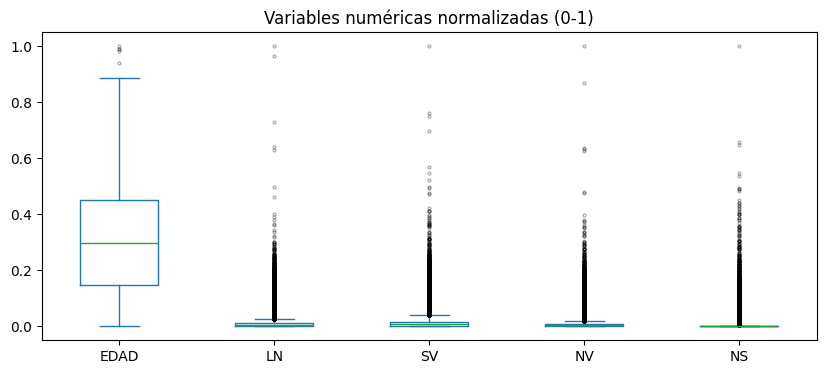

,min,q1,q2 (mediana),q3,max,media
EDAD,18.000,35.000,52.000,70.000,140.000,52.699
LN,1.000,3.000,6.000,12.000,982.000,9.450
SV,0.000,1.000,3.000,7.000,424.000,4.933
NV,0.000,1.000,2.000,5.000,603.000,4.086
NS,0.000,0.000,0.000,0.000,259.000,0.430


In [70]:
VARS_NUM = ["EDAD", "LN", "SV", "NV", "NS"]
muestra = data[VARS_NUM].sample(500_000, random_state=1)   # muestra solo para dibujar

# Normalización min-max (0-1) para ver las variables en el mismo eje
norm = (muestra - muestra.min()) / (muestra.max() - muestra.min())
norm.plot(kind="box", figsize=(10, 4), flierprops={"markersize": 2, "alpha": 0.3},
          title="Variables numéricas normalizadas (0-1)")
plt.show()

# Resumen estadístico con todos los datos
data[VARS_NUM].describe().loc[["min", "25%", "50%", "75%", "max", "mean"]].T.rename(
    columns={"25%": "q1", "50%": "q2 (mediana)", "75%": "q3", "mean": "media"})


In [94]:
def limites_tukey(valores):
    q1, q3 = valores.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

# 1) Por filas (lo que muestra el boxplot)
inf, sup = limites_tukey(data["EDAD"])
fuera = (data["EDAD"] < inf) | (data["EDAD"] > sup)
print(f"Límites Tukey por filas: [{inf}, {sup}]")
print(f"Filas outlier: {fuera.sum():,} ({fuera.mean():.4%} de las filas)")
print(f"Personas (LN) en esas filas: {data.loc[fuera, 'LN'].sum():,} "
      f"({data.loc[fuera, 'LN'].sum() / data['LN'].sum():.4%} de la LN)")

# 2) Ponderado por LN: el IQR de las personas, no de las filas
edades = data.groupby("EDAD")["LN"].sum().sort_index()
acum = edades.cumsum() / edades.sum()
q1 = acum[acum >= 0.25].index[0]
q3 = acum[acum >= 0.75].index[0]
inf_p, sup_p = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
ln_fuera = edades[(edades.index < inf_p) | (edades.index > sup_p)].sum()
print(f"\nLímites Tukey ponderados por LN: [{inf_p}, {sup_p}]")
print(f"Personas (LN) outlier: {ln_fuera:,} ({ln_fuera / edades.sum():.4%} de la LN)")

# Cuántas filas y personas hay por edad en el extremo superior
print(edades[edades.index > 90].to_frame("LN").assign(
    filas=data[data["EDAD"] > 90].groupby("EDAD").size()))


Límites Tukey por filas: [-17.5, 122.5]
Filas outlier: 286 (0.0005% de las filas)
Personas (LN) en esas filas: 286 (0.0001% de la LN)

Límites Tukey ponderados por LN: [-9.5, 90.5]
Personas (LN) outlier: 1,874,204 (0.3615% de la LN)
          LN   filas
EDAD                
91    404810  288049
92    324540  243621
93    264767  207027
94    220295  179226
95    167703  141958
96    126012  110212
97     98853   89028
98     79863   72361
99     55942   51927
100    37329   35607
101    26226   25277
102    18205   17676
103    14128   13744
104    10178    9941
105     6678    6574
106     4740    4683
107     3630    3593
108     3813    3715
109     2173    2138
110      962     957
111      680     679
112      503     501
113      478     478
114      328     328
115      269     267
116      191     191
117      214     211
118      178     162
119       77      77
120       66      66
121       56      54
122       31      31
123       39      39
124       36      36
125       2

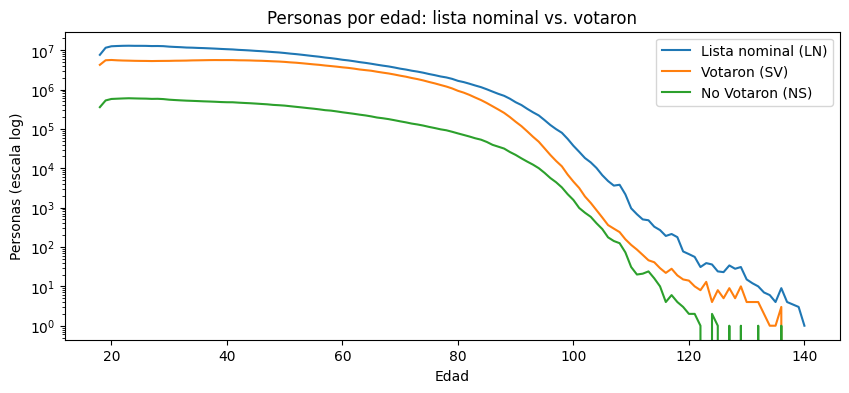

In [96]:
por_edad = data.groupby("EDAD")[["LN", "SV", "NS"]].sum().sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(por_edad.index, por_edad["LN"], label="Lista nominal (LN)")
ax.plot(por_edad.index, por_edad["SV"], label="Votaron (SV)")
ax.plot(por_edad.index, por_edad["NS"], label="No Votaron (NS)")
ax.set_yscale("log")   # escala logarítmica: las edades altas tienen muy pocas personas
ax.set_xlabel("Edad")
ax.set_ylabel("Personas (escala log)")
ax.set_title("Personas por edad: lista nominal vs. votaron")
ax.legend()
plt.show()


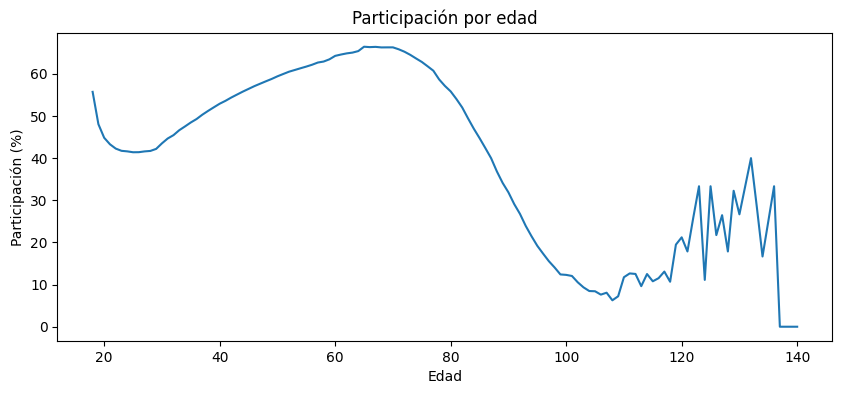

In [99]:
por_edad["participacion_%"] = por_edad["SV"] / por_edad["LN"] * 100

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(por_edad.index, por_edad["participacion_%"])
ax.set_xlabel("Edad")
ax.set_ylabel("Participación (%)")
ax.set_title("Participación por edad")
plt.show()


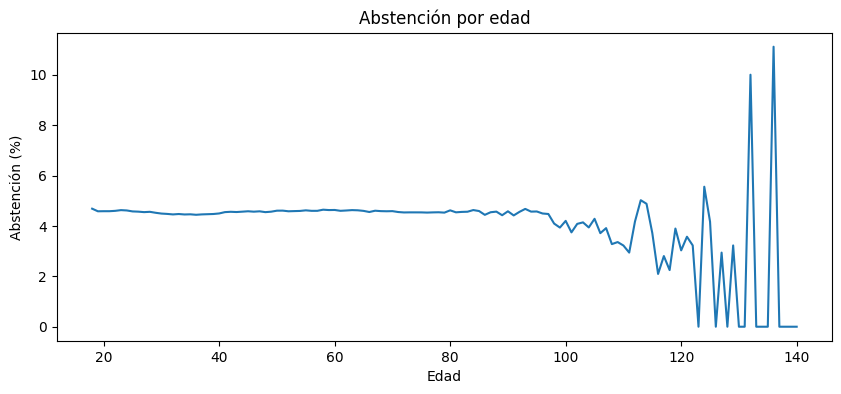

In [100]:
por_edad["abstencion_%"] = por_edad["NS"] / por_edad["LN"] * 100

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(por_edad.index, por_edad["abstencion_%"])
ax.set_xlabel("Edad")
ax.set_ylabel("Abstención (%)")
ax.set_title("Abstención por edad")
plt.show()


In [103]:
menores = data[data["EDAD"] < 18]
print(menores.groupby("EDAD")["LN"].agg(filas="size", personas="sum"))

Empty DataFrame
Columns: [filas, personas]
Index: []


## 4. Histogramas

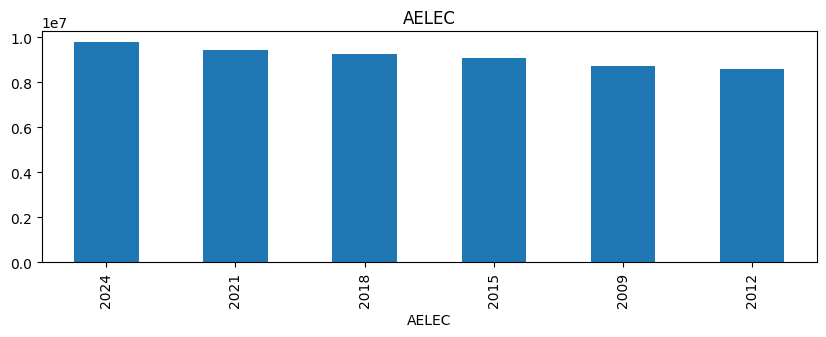

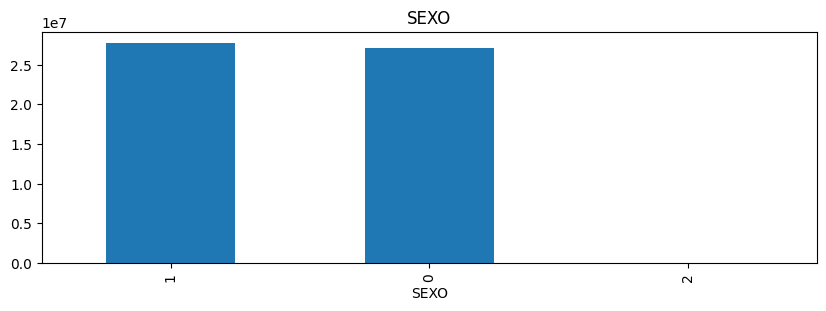

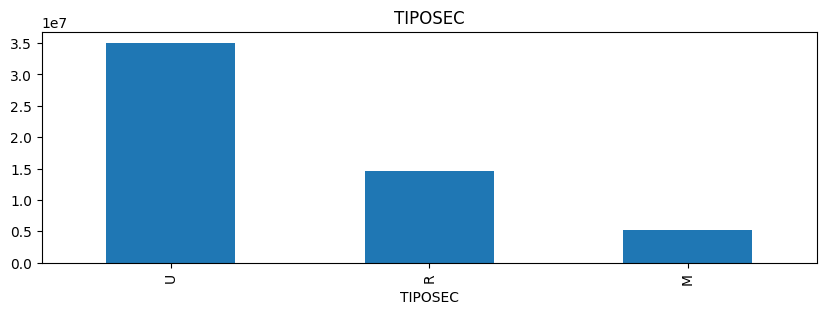

In [71]:
VARS_CAT = ["AELEC", "SEXO", "TIPOSEC"]

for col in VARS_CAT:
    serie = data[col]
    if col == "DEF":
        serie = pd.to_numeric(serie, errors="coerce").astype("Int16")   # DEF mezcla números y espacios
    serie.value_counts(dropna=False).head(20).plot(kind="bar", figsize=(10, 3), title=col)
    plt.show()


## 5. Estados

In [72]:
estados = data["EDONOM"].value_counts().sort_index()
print(f"Valores distintos en EDONOM: {len(estados)}\n")
estados

Valores distintos en EDONOM: 33



EDONOM
AGUASCALIENTES          494439
BAJA CALIFORNIA        1478506
BAJA CALIFORNIA SUR     348336
CAMPECHE                411597
CHIAPAS                1724737
CHIHUAHUA              2330854
CIUDAD DE MEXICO       1609788
COAHUILA               1317781
COLIMA                  300944
DISTRITO FEDERAL       3165152
DURANGO                1060760
GUANAJUATO             2601391
GUERRERO               2104967
HIDALGO                1412101
JALISCO                2999641
MEXICO                 5326834
MICHOACAN              2257344
MORELOS                 777442
NAYARIT                 748261
NUEVO LEON             2062261
OAXACA                 2050122
PUEBLA                 2277286
QUERETARO               706806
QUINTANA ROO            659366
SAN LUIS POTOSI        1444555
SINALOA                2683213
SONORA                 1181180
TABASCO                 943419
TAMAULIPAS             1607151
TLAXCALA                501305
VERACRUZ               4018791
YUCATAN                 922146
Z

In [73]:
data_estados = data.copy()
data_estados["EDONOM"] = data_estados["EDONOM"].replace({"DISTRITO FEDERAL": "CIUDAD DE MEXICO"})

In [74]:
estados = data_estados["EDONOM"].value_counts().sort_index()
print(f"Valores distintos en EDONOM: {len(estados)}\n")
estados

Valores distintos en EDONOM: 32



EDONOM
AGUASCALIENTES          494439
BAJA CALIFORNIA        1478506
BAJA CALIFORNIA SUR     348336
CAMPECHE                411597
CHIAPAS                1724737
CHIHUAHUA              2330854
CIUDAD DE MEXICO       4774940
COAHUILA               1317781
COLIMA                  300944
DURANGO                1060760
GUANAJUATO             2601391
GUERRERO               2104967
HIDALGO                1412101
JALISCO                2999641
MEXICO                 5326834
MICHOACAN              2257344
MORELOS                 777442
NAYARIT                 748261
NUEVO LEON             2062261
OAXACA                 2050122
PUEBLA                 2277286
QUERETARO               706806
QUINTANA ROO            659366
SAN LUIS POTOSI        1444555
SINALOA                2683213
SONORA                 1181180
TABASCO                 943419
TAMAULIPAS             1607151
TLAXCALA                501305
VERACRUZ               4018791
YUCATAN                 922146
ZACATECAS              1344236
N

## 6. Distritos Electorales

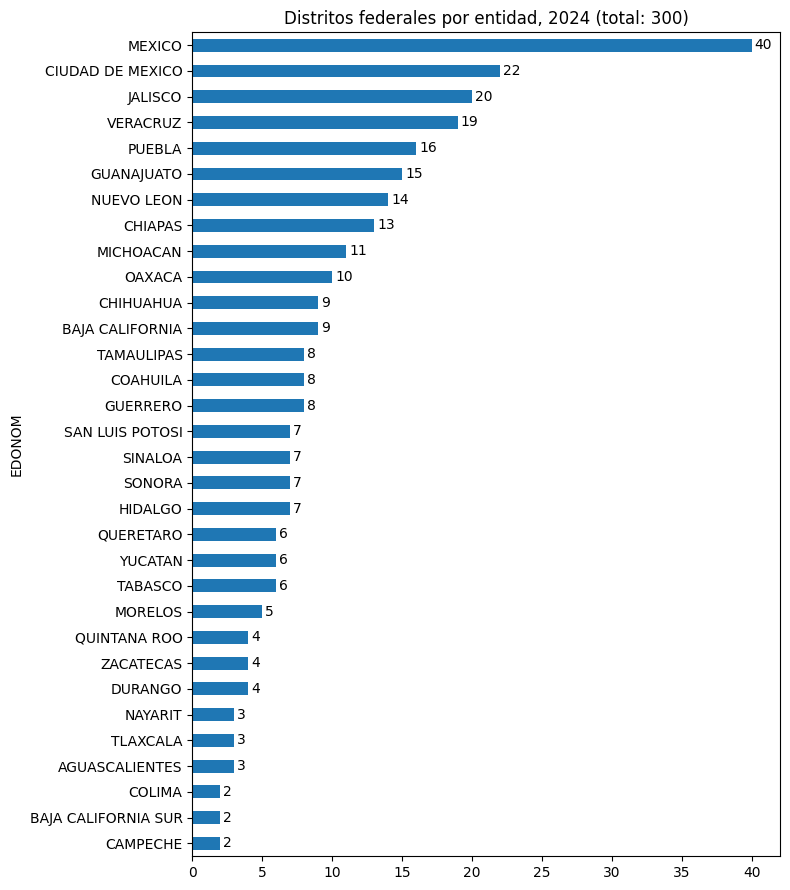

In [75]:
ult = data_estados[data_estados["AELEC"] == 2024]
pares = pd.DataFrame({"EDONOM": ult["EDONOM"], "DEF": pd.to_numeric(ult["DEF"], errors="coerce")}).drop_duplicates().dropna()
distritos = pares.groupby("EDONOM", observed=True)["DEF"].nunique().sort_values()

ax = distritos.plot(kind="barh", figsize=(8, 9), title=f"Distritos federales por entidad, 2024 (total: {distritos.sum()})")
ax.bar_label(ax.containers[0], padding=2)
plt.tight_layout()
plt.show()

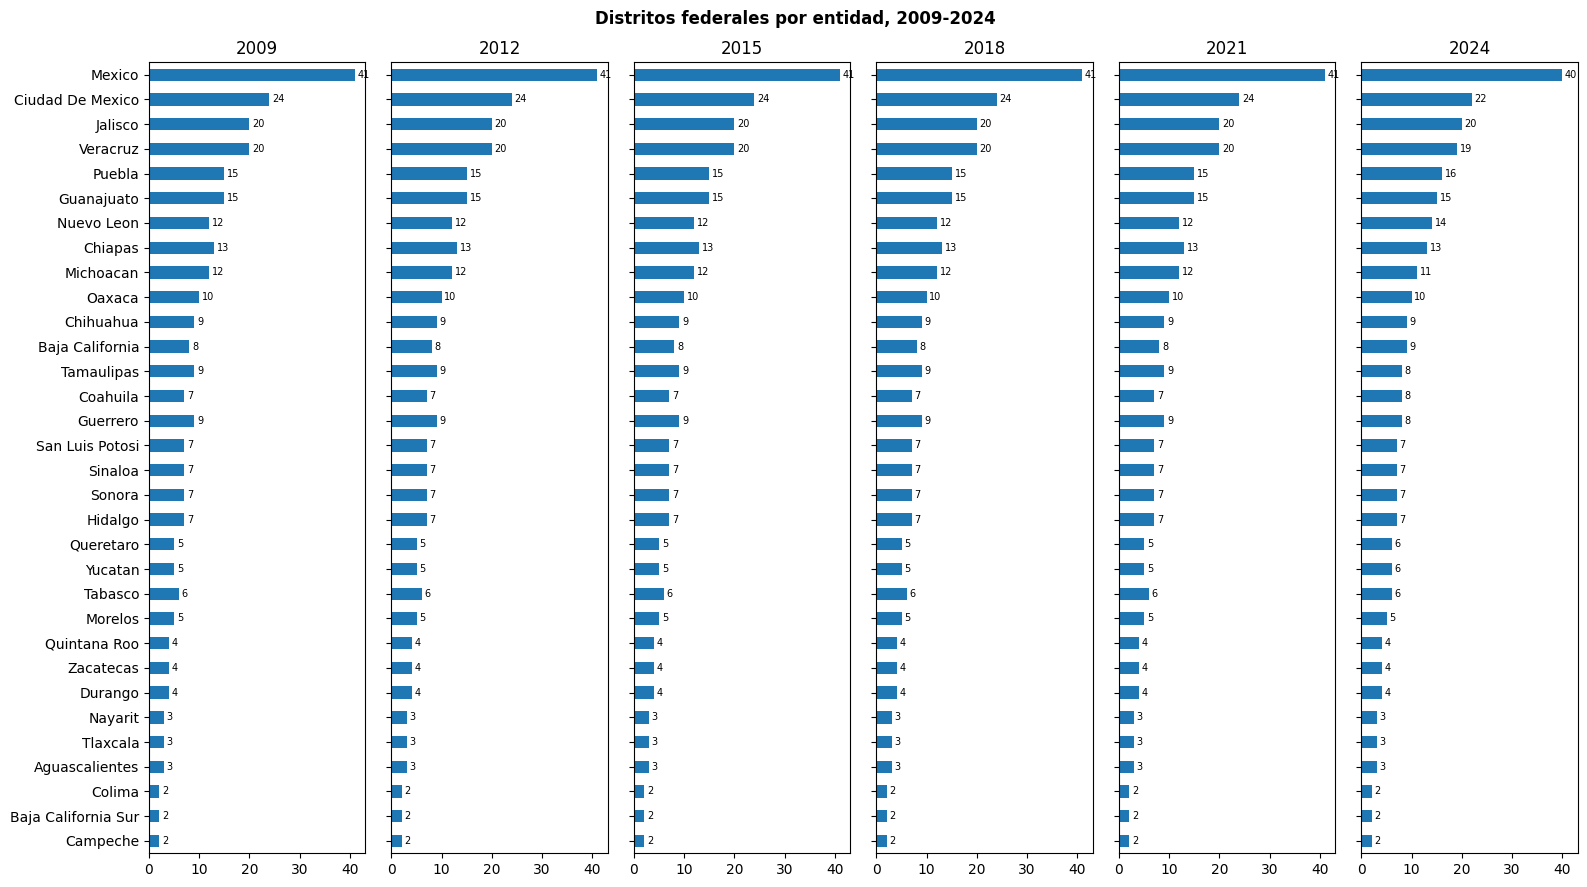

AELEC
2009    300
2012    300
2015    300
2018    300
2021    300
2024    300
dtype: int64

In [76]:
pares = pd.DataFrame({"AELEC": data_estados["AELEC"], "EDONOM": data_estados["EDONOM"], "DEF": pd.to_numeric(data_estados["DEF"], errors="coerce")}).drop_duplicates().dropna()
pares["EDONOM"] = pares["EDONOM"].astype(str).replace({"DISTRITO FEDERAL": "CIUDAD DE MEXICO"})   # misma entidad con dos nombres
matriz = pares.drop_duplicates().groupby(["EDONOM", "AELEC"])["DEF"].nunique().unstack()
matriz.index = matriz.index.str.title()
matriz = matriz.sort_values(2024)

fig, axes = plt.subplots(1, matriz.shape[1], figsize=(16, 9), sharey=True, sharex=True)
for ax, anio in zip(axes, matriz.columns):
    matriz[anio].plot(kind="barh", ax=ax, title=str(anio))
    ax.bar_label(ax.containers[0], fontsize=7, padding=2)
    ax.set_ylabel("")
fig.suptitle("Distritos federales por entidad, 2009-2024", fontweight="bold")
plt.tight_layout()
plt.show()

matriz.sum()


In [89]:
vacios = pd.to_numeric(data_estados["DEF"], errors="coerce").isna()
print(f"Registros con DEF vacío: {vacios.sum():,} de {len(data_estados):,} ({vacios.mean() * 100:.3f} %)\n")
display(vacios.groupby(data_estados["AELEC"]).agg(["sum", "mean"]).rename(columns={"sum": "vacíos", "mean": "proporción del año"}))

"""
posiciones = np.flatnonzero(vacios.values)
elegidas = np.sort(np.random.default_rng(1).choice(posiciones, 5, replace=False))
for i in elegidas:
    print(f"\n--- Registro vacío en la posición {i:,}: 5 filas antes y 5 después ---")
    display(data_estados.iloc[i - 5: i + 6].assign(DEF_vacío=vacios.iloc[i - 5: i + 6]))
"""


Registros con DEF vacío: 44,154 de 54,872,712 (0.080 %)



,vacíos,proporción del año
AELEC,,
2009,28477,0.003
2012,15677,0.002
2015,0,0.000
2018,0,0.000
2021,0,0.000
2024,0,0.000


'\nposiciones = np.flatnonzero(vacios.values)\nelegidas = np.sort(np.random.default_rng(1).choice(posiciones, 5, replace=False))\nfor i in elegidas:\n    print(f"\n--- Registro vacío en la posición {i:,}: 5 filas antes y 5 después ---")\n    display(data_estados.iloc[i - 5: i + 6].assign(DEF_vacío=vacios.iloc[i - 5: i + 6]))\n'

## 7. Mapa de correlación

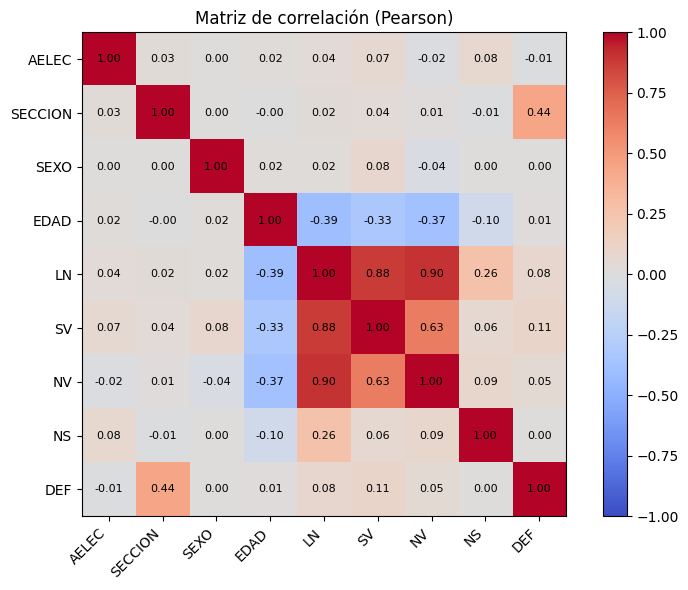

In [77]:
num = data_estados.select_dtypes("number").copy()
num["DEF"] = pd.to_numeric(data_estados["DEF"], errors="coerce")
corr = num.corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax)
ax.set_title("Matriz de correlación (Pearson)")
plt.tight_layout()
plt.show()


## 8. Participación

In [91]:
part = data_estados.copy()
part["PARTICIPACIÓN"] = part["SV"] 
part["ABSTENCIÓN"] = part["NV"] 

part.head()

,AELEC,FELECCION,EDONOM,MPIONOM,SECCION,DEF,TIPOSEC,SEXO,EDAD,LN,SV,NV,NS,PARTICIPACIÓN,ABSTENCIÓN
0,2009,5/7/2009,AGUASCALIENTES,Aguascalientes,1,3,U,0,18,31,11,20,0,11,20
1,2009,5/7/2009,AGUASCALIENTES,Aguascalientes,1,3,U,0,19,20,7,13,0,7,13
2,2009,5/7/2009,AGUASCALIENTES,Aguascalientes,1,3,U,0,20,28,9,19,0,9,19
3,2009,5/7/2009,AGUASCALIENTES,Aguascalientes,1,3,U,0,21,21,9,12,0,9,12
4,2009,5/7/2009,AGUASCALIENTES,Aguascalientes,1,3,U,0,22,30,12,18,0,12,18


AELEC,2009,2012,2015,2018,2021,2024
nacional,0.430,0.619,0.442,0.581,0.496,0.558



Participación por entidad y año


AELEC,2009,2012,2015,2018,2021,2024
EDONOM,,,,,,
AGUASCALIENTES,0.377,0.589,0.349,0.571,0.481,0.571
BAJA CALIFORNIA,0.291,0.522,0.295,0.504,0.351,0.437
BAJA CALIFORNIA SUR,0.320,0.570,0.421,0.530,0.456,0.506
CAMPECHE,0.613,0.661,0.519,0.620,0.570,0.536
CHIAPAS,0.379,0.660,0.431,0.610,0.550,0.545
CHIHUAHUA,0.300,0.516,0.302,0.470,0.400,0.441
CIUDAD DE MEXICO,0.404,0.661,0.420,0.680,0.510,0.680
COAHUILA,0.435,0.609,0.430,0.595,0.553,0.553
COLIMA,0.573,0.620,0.542,0.606,0.511,0.550



Participación por sexo y año


AELEC,2009,2012,2015,2018,2021,2024
SEXO,,,,,,
0,0.395,0.576,0.403,0.542,0.457,0.512
1,0.462,0.659,0.478,0.618,0.532,0.601
2,NaN,NaN,NaN,NaN,NaN,0.752


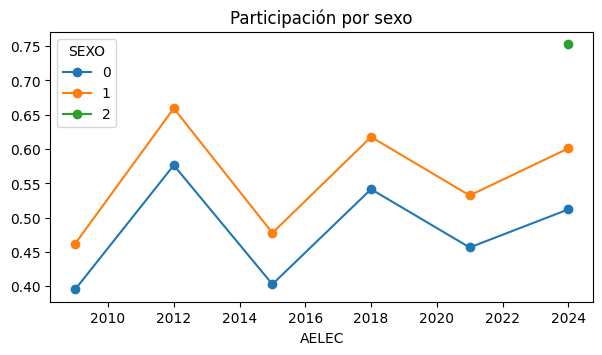


Participación por grupo de edad y año


AELEC,2009,2012,2015,2018,2021,2024
GRUPO_EDAD,,,,,,
18-19,0.429,0.619,0.415,0.564,0.494,0.531
20-29,0.340,0.530,0.334,0.492,0.389,0.447
30-39,0.389,0.580,0.403,0.558,0.436,0.504
40-49,0.474,0.672,0.483,0.618,0.525,0.581
50-59,0.535,0.721,0.536,0.657,0.588,0.639
60-69,0.565,0.737,0.585,0.681,0.640,0.699
70-79,0.527,0.693,0.567,0.654,0.630,0.692
80+,0.309,0.494,0.384,0.461,0.433,0.513


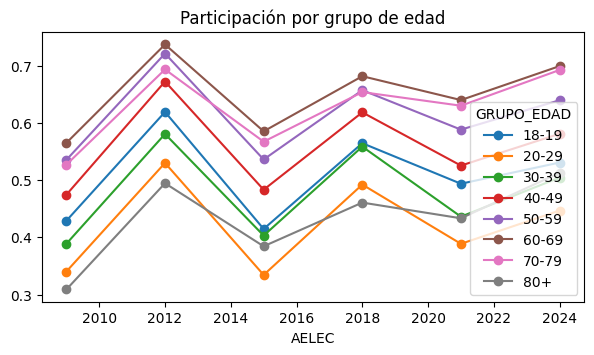


Participación por tipo de sección y año


AELEC,2009,2012,2015,2018,2021,2024
TIPOSEC,,,,,,
M,0.436,0.612,0.454,0.566,0.499,0.542
R,0.468,0.640,0.514,0.591,0.552,0.557
U,0.418,0.615,0.421,0.582,0.481,0.562


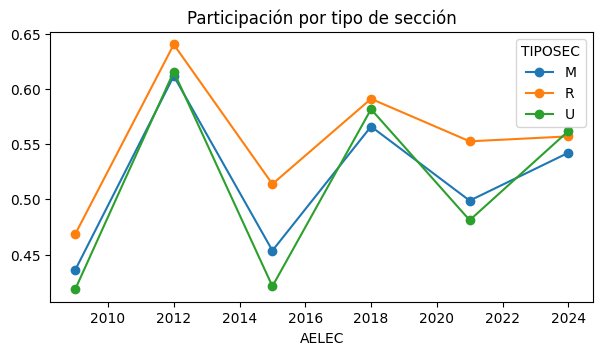

In [82]:
part["EDONOM"] = part["EDONOM"].replace({"DISTRITO FEDERAL": "CIUDAD DE MEXICO"})   # misma entidad con dos nombres
part["GRUPO_EDAD"] = pd.cut(part["EDAD"], [17, 19, 29, 39, 49, 59, 69, 79, 200],
                            labels=["18-19", "20-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"])

def participacion(por):
    """Participación = PARTICIPACIÓN / (PARTICIPACIÓN + ABSTENCIÓN), agrupada por las columnas indicadas."""
    t = part.groupby(por, observed=True)[["PARTICIPACIÓN", "ABSTENCIÓN"]].sum()
    return t["PARTICIPACIÓN"] / (t["PARTICIPACIÓN"] + t["ABSTENCIÓN"])

display(participacion("AELEC").to_frame("nacional").T)

dimensiones = {"Entidad": "EDONOM", "Sexo": "SEXO", "Grupo de edad": "GRUPO_EDAD", "Tipo de sección": "TIPOSEC"}
for nombre, col in dimensiones.items():
    tabla = participacion([col, "AELEC"]).unstack()
    print(f"\nParticipación por {nombre.lower()} y año")
    display(tabla)
    if nombre != "Entidad":
        tabla.T.plot(marker="o", figsize=(7, 3.5), title=f"Participación por {nombre.lower()}")
        plt.show()


## 9. Abstención

AELEC,2009,2012,2015,2018,2021,2024
nacional,0.570,0.381,0.558,0.419,0.504,0.442



Abstención por entidad y año


AELEC,2009,2012,2015,2018,2021,2024
EDONOM,,,,,,
AGUASCALIENTES,0.623,0.411,0.651,0.429,0.519,0.429
BAJA CALIFORNIA,0.709,0.478,0.705,0.496,0.649,0.563
BAJA CALIFORNIA SUR,0.680,0.430,0.579,0.470,0.544,0.494
CAMPECHE,0.387,0.339,0.481,0.380,0.430,0.464
CHIAPAS,0.621,0.340,0.569,0.390,0.450,0.455
CHIHUAHUA,0.700,0.484,0.698,0.530,0.600,0.559
CIUDAD DE MEXICO,0.596,0.339,0.580,0.320,0.490,0.320
COAHUILA,0.565,0.391,0.570,0.405,0.447,0.447
COLIMA,0.427,0.380,0.458,0.394,0.489,0.450



Abstención por sexo y año


AELEC,2009,2012,2015,2018,2021,2024
SEXO,,,,,,
0,0.605,0.424,0.597,0.458,0.543,0.488
1,0.538,0.341,0.522,0.382,0.468,0.399
2,NaN,NaN,NaN,NaN,NaN,0.248


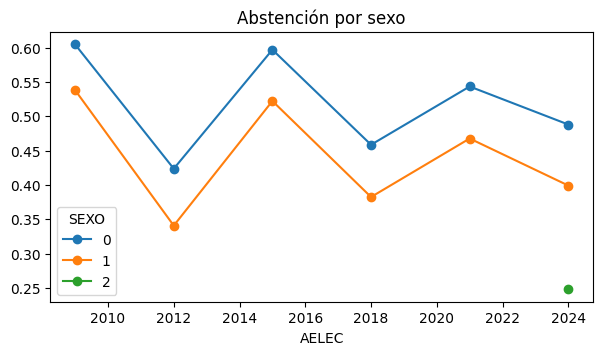


Abstención por grupo de edad y año


AELEC,2009,2012,2015,2018,2021,2024
GRUPO_EDAD,,,,,,
18-19,0.571,0.381,0.585,0.436,0.506,0.469
20-29,0.660,0.470,0.666,0.508,0.611,0.553
30-39,0.611,0.420,0.597,0.442,0.564,0.496
40-49,0.526,0.328,0.517,0.382,0.475,0.419
50-59,0.465,0.279,0.464,0.343,0.412,0.361
60-69,0.435,0.263,0.415,0.319,0.360,0.301
70-79,0.473,0.307,0.433,0.346,0.370,0.308
80+,0.691,0.506,0.616,0.539,0.567,0.487


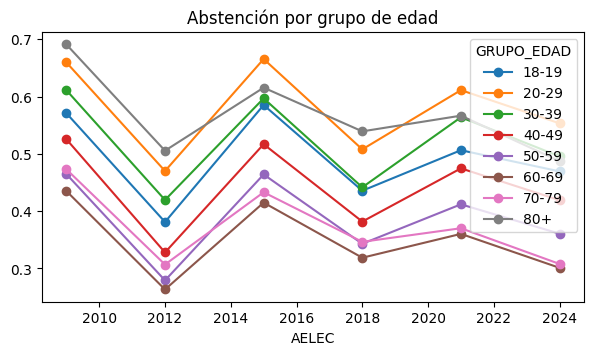


Abstención por tipo de sección y año


AELEC,2009,2012,2015,2018,2021,2024
TIPOSEC,,,,,,
M,0.564,0.388,0.546,0.434,0.501,0.458
R,0.532,0.360,0.486,0.409,0.448,0.443
U,0.582,0.385,0.579,0.418,0.519,0.438


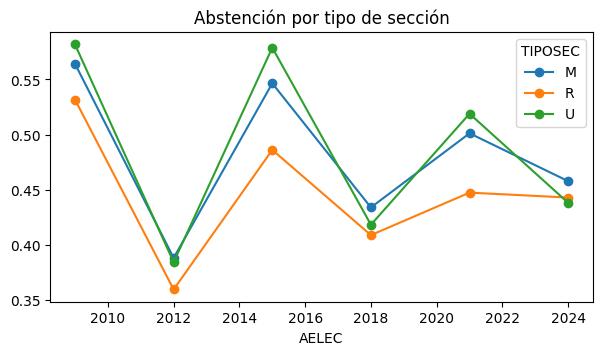

In [83]:
part["EDONOM"] = part["EDONOM"].replace({"DISTRITO FEDERAL": "CIUDAD DE MEXICO"})   # misma entidad con dos nombres
part["GRUPO_EDAD"] = pd.cut(part["EDAD"], [17, 19, 29, 39, 49, 59, 69, 79, 200],
                            labels=["18-19", "20-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"])

def abstencion(por):
    """Abstención = ABSTENCIÓN / (PARTICIPACIÓN + ABSTENCIÓN), agrupada por las columnas indicadas."""
    t = part.groupby(por, observed=True)[["PARTICIPACIÓN", "ABSTENCIÓN"]].sum()
    return t["ABSTENCIÓN"] / (t["PARTICIPACIÓN"] + t["ABSTENCIÓN"])

display(abstencion("AELEC").to_frame("nacional").T)

dimensiones = {"Entidad": "EDONOM", "Sexo": "SEXO", "Grupo de edad": "GRUPO_EDAD", "Tipo de sección": "TIPOSEC"}
for nombre, col in dimensiones.items():
    tabla = abstencion([col, "AELEC"]).unstack()
    print(f"\nAbstención por {nombre.lower()} y año")
    display(tabla)
    if nombre != "Entidad":
        tabla.T.plot(marker="o", figsize=(7, 3.5), title=f"Abstención por {nombre.lower()}")
        plt.show()


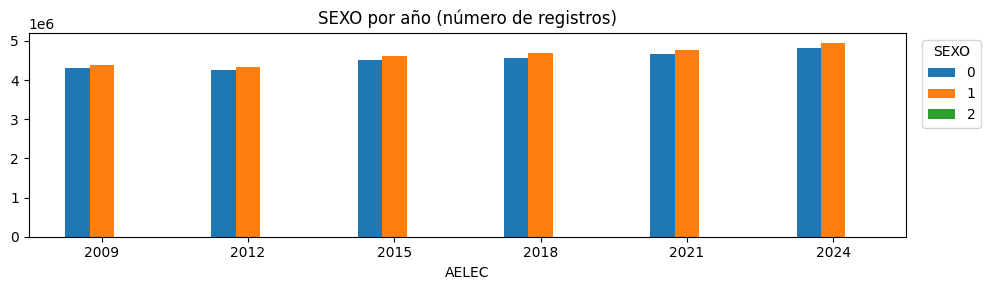

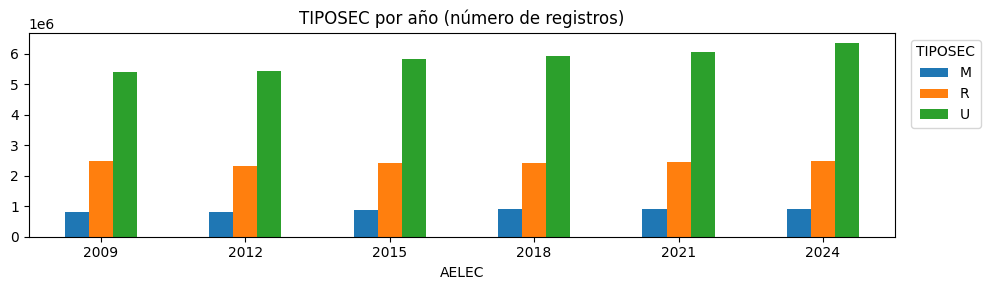

In [84]:
VARS_CAT = ["SEXO", "TIPOSEC"]

for col in VARS_CAT:
    ax = pd.crosstab(part["AELEC"], part[col]).plot(kind="bar", figsize=(10, 3), rot=0, title=f"{col} por año (número de registros)")
    ax.legend(title=col, bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.tight_layout(); plt.show()


## 10. Sexo

In [85]:
t = data.groupby("SEXO").agg(registros=("LN", "size"), lista_nominal=("LN", "sum"))
t["% registros"] = t["registros"] / t["registros"].sum() * 100
t["% lista nominal"] = t["lista_nominal"] / t["lista_nominal"].sum() * 100
t["por millón de personas"] = t["lista_nominal"] / t["lista_nominal"].sum() * 1_000_000
t

,registros,lista_nominal,% registros,% lista nominal,por millón de personas
SEXO,,,,,
0,27128199,249602819,49.438,48.137,"481,372.953"
1,27744408,268919809,50.561,51.863,"518,626.845"
2,105,105,0.000,0.000,0.202


## 11. Fechas de elección

In [101]:
print(part.groupby("AELEC")["FELECCION"].unique())

AELEC
2009      [5/7/2009]
2012      [1/7/2012]
2015      [7/6/2015]
2018      [1/7/2018]
2021      [6/6/2021]
2024    [06/02/2024]
Name: FELECCION, dtype: object


## 12. Tipo de sección

In [102]:
print(part["TIPOSEC"].value_counts(dropna=False))

TIPOSEC
U    35056381
R    14584179
M     5232152
Name: count, dtype: int64


In [106]:
import re
import unicodedata

def normalizar(texto):
    # quita acentos, pasa a mayúsculas, quita puntuación y espacios de más
    texto = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    texto = re.sub(r"[^A-Z0-9 ]", "", texto.upper())
    return re.sub(r"\s+", " ", texto).strip()

# Combinaciones distintas (pocas), para no normalizar 54 millones de filas
mun = part[["AELEC", "EDONOM", "MPIONOM"]].drop_duplicates().copy()
mun["ESTADO"] = mun["EDONOM"].map(normalizar).replace({"DISTRITO FEDERAL": "CIUDAD DE MEXICO"})
mun["MUNICIPIO"] = mun["MPIONOM"].map(normalizar)
mun = mun[["AELEC", "ESTADO", "MUNICIPIO"]].drop_duplicates()

# Años en que aparece cada municipio
presencia = mun.groupby(["ESTADO", "MUNICIPIO"])["AELEC"].apply(list).reset_index(name="anios")
presencia["n_anios"] = presencia["anios"].str.len()

# Los que no aparecen en los 6 años, ordenados para compararlos a ojo
incompletos = presencia[presencia["n_anios"] < 6].sort_values(["ESTADO", "MUNICIPIO"])
print(f"\nMunicipios: {len(presencia)} | en los 6 años: {(presencia['n_anios'] == 6).sum()} | incompletos: {len(incompletos)}")
print(incompletos.to_string(index=False))

# Nombres repetidos en más de un estado
repetidos = presencia.groupby("MUNICIPIO")["ESTADO"].nunique()
print(f"\nNombres presentes en más de un estado: {(repetidos > 1).sum()}")



Municipios: 2508 | en los 6 años: 2423 | incompletos: 85
         ESTADO                                                                   MUNICIPIO                          anios  n_anios
BAJA CALIFORNIA                                                                  SAN FELIPE                         [2024]        1
BAJA CALIFORNIA                                                                 SAN QUINTIN                         [2024]        1
       CAMPECHE                                                                  DZITBALCHE                         [2024]        1
       CAMPECHE                                                                  DZITBLACHE                         [2021]        1
       CAMPECHE                                                                  HOPELCHEEN                         [2024]        1
       CAMPECHE                                                                   HOPELCHEN [2009, 2012, 2015, 2018, 2021]        5
       CAMPECHE   